In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_rt = pd.read_csv('returns_clean.csv')
df_o = pd.read_csv('orders_clean.csv')
df_pr = pd.read_csv('products_clean.csv')

In [3]:
df_rt.info()

<class 'pandas.DataFrame'>
RangeIndex: 2092 entries, 0 to 2091
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   return_id      2092 non-null   str    
 1   order_id       2092 non-null   str    
 2   product_id     2092 non-null   str    
 3   return_date    2092 non-null   str    
 4   return_reason  2092 non-null   str    
 5   refund_amount  2092 non-null   float64
 6   sales_amount   2092 non-null   float64
dtypes: float64(2), str(5)
memory usage: 200.0 KB


In [4]:
df_rt['return_date'] = pd.to_datetime(df_rt['return_date'])

In [5]:
df_rt.info()

<class 'pandas.DataFrame'>
RangeIndex: 2092 entries, 0 to 2091
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   return_id      2092 non-null   str           
 1   order_id       2092 non-null   str           
 2   product_id     2092 non-null   str           
 3   return_date    2092 non-null   datetime64[us]
 4   return_reason  2092 non-null   str           
 5   refund_amount  2092 non-null   float64       
 6   sales_amount   2092 non-null   float64       
dtypes: datetime64[us](1), float64(2), str(4)
memory usage: 179.6 KB


In [6]:
df_pr.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   product_id     600 non-null    str    
 1   product_name   600 non-null    str    
 2   category       600 non-null    str    
 3   sub_category   600 non-null    str    
 4   list_price     600 non-null    float64
 5   unit_cost      600 non-null    float64
 6   seller_id      600 non-null    str    
 7   quality_score  600 non-null    float64
dtypes: float64(3), str(5)
memory usage: 67.9 KB


In [7]:
df_pr['category'].unique()

<ArrowStringArray>
[         'Books',     'Electronic',         'Sports', 'Home & Kitchen',
        'Fashion',        'Grocery',         'Beauty',    'Electronics',
           'Toys']
Length: 9, dtype: str

In [8]:
df_pr['category'] = df_pr['category'].replace({'Electronic':'Electronics'})

In [11]:
df_pr['category'].unique()

<ArrowStringArray>
[         'Books',    'Electronics',         'Sports', 'Home & Kitchen',
        'Fashion',        'Grocery',         'Beauty',           'Toys']
Length: 8, dtype: str

In [12]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   order_id       29951 non-null  str    
 1   customer_id    29065 non-null  str    
 2   order_date     29951 non-null  str    
 3   product_id     29951 non-null  str    
 4   seller_id      29951 non-null  str    
 5   quantity       29951 non-null  int64  
 6   list_price     29951 non-null  float64
 7   discount_pct   29951 non-null  int64  
 8   sales_amount   29951 non-null  float64
 9   cost_amount    29951 non-null  float64
 10  profit         29951 non-null  float64
 11  order_status   29951 non-null  str    
 12  shipping_days  29951 non-null  float64
dtypes: float64(5), int64(2), str(6)
memory usage: 4.2 MB


In [13]:
df_o['order_date'] = pd.to_datetime(df_o['order_date'])

In [14]:
df_o['shipping_days'].unique()

array([5., 6., 9., 4., 2., 7., 3., 8.])

In [15]:
df_o['shipping_days'] = df_o['shipping_days'].astype(int)

In [16]:
df_o.info()

<class 'pandas.DataFrame'>
RangeIndex: 29951 entries, 0 to 29950
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   order_id       29951 non-null  str           
 1   customer_id    29065 non-null  str           
 2   order_date     29951 non-null  datetime64[us]
 3   product_id     29951 non-null  str           
 4   seller_id      29951 non-null  str           
 5   quantity       29951 non-null  int64         
 6   list_price     29951 non-null  float64       
 7   discount_pct   29951 non-null  int64         
 8   sales_amount   29951 non-null  float64       
 9   cost_amount    29951 non-null  float64       
 10  profit         29951 non-null  float64       
 11  order_status   29951 non-null  str           
 12  shipping_days  29951 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(3), str(5)
memory usage: 3.9 MB


### 1. Total money lost to returns

In [19]:
df = df_o[df_o['order_status'] != 'Cancelled']

In [20]:
df.head()

,order_id,customer_id,order_date,product_id,seller_id,quantity,list_price,discount_pct,sales_amount,cost_amount,profit,order_status,shipping_days
0,O008252,C01720,2023-11-16,P0072,S0056,5,153.74,10,691.83,579.55,112.28,Delivered,5
1,O019782,C04502,2024-08-24,P0316,S0117,1,418.61,0,418.61,293.04,125.57,Delivered,6
3,O025510,C01368,2023-11-30,P0419,S0164,1,1469.72,10,1322.75,832.23,490.52,Delivered,9
4,O000483,C00041,2024-08-10,P0539,S0141,3,525.70,0,1577.10,1113.24,463.86,Delivered,4
5,O020103,C00504,2023-07-09,P0203,S0181,1,1229.10,10,1106.19,1082.30,23.89,Delivered,2


In [21]:
## Revenue:
Revenue = df['sales_amount'].sum()

In [23]:
Revenue

np.float64(139720161.17)

In [28]:
print('Revenue :',Revenue/1e6)

Revenue : 139.72016116999998


In [29]:
## Profit:

Profit = df['profit'].sum()

In [30]:
Profit

np.float64(30698410.65)

In [31]:
print('Profit :', Profit/1e6)

Profit : 30.69841065


In [32]:
df_rt.head()

,return_id,order_id,product_id,return_date,return_reason,refund_amount,sales_amount
0,RET01729,O024764,P0172,2023-07-21,Size/Fit Issue,2441.66,2441.66
1,RET01379,O019631,P0206,2024-03-09,Wrong Item,770.10,770.10
2,RET00985,O013896,P0419,2023-10-19,Defective,1469.72,1469.72
3,RET00242,O003589,P0339,2025-01-15,Defective,9756.60,9756.60
4,RET00135,O002037,P0172,2023-05-16,Defective,1953.33,1953.33


In [34]:
## Refund:
Refund = df_rt['refund_amount'].sum()

In [35]:
Refund

np.float64(9748823.780000001)

In [37]:
print('Refund :', Refund/1e6)

Refund : 9.74882378


In [38]:
print('Revenue (M):', round(Revenue / 1e6, 1))
print('Refunds (M):', round(Refund / 1e6, 2))
print('Refund % of revenue:', round(Refund / Revenue * 100, 1))
print('Net revenue (M):', round((Revenue - Refund) / 1e6, 1))
print('Refund as % of profit:', round(Refund / Profit * 100, 1))
print('Average refund:', round(df_rt['refund_amount'].mean()))

Revenue (M): 139.7
Refunds (M): 9.75
Refund % of revenue: 7.0
Net revenue (M): 130.0
Refund as % of profit: 31.8
Average refund: 4660


### 2. Refunds by category

In [39]:
df_o.columns

Index(['order_id', 'customer_id', 'order_date', 'product_id', 'seller_id',
       'quantity', 'list_price', 'discount_pct', 'sales_amount', 'cost_amount',
       'profit', 'order_status', 'shipping_days'],
      dtype='str')

In [41]:
df_rt.columns

Index(['return_id', 'order_id', 'product_id', 'return_date', 'return_reason',
       'refund_amount', 'sales_amount'],
      dtype='str')

In [42]:
df_pr.columns

Index(['product_id', 'product_name', 'category', 'sub_category', 'list_price',
       'unit_cost', 'seller_id', 'quality_score'],
      dtype='str')

In [45]:
rc = df_rt.merge(df_pr[['product_id', 'category']], on = 'product_id', how = 'left')

In [47]:
rc.head()

,return_id,order_id,product_id,return_date,return_reason,refund_amount,sales_amount,category
0,RET01729,O024764,P0172,2023-07-21,Size/Fit Issue,2441.66,2441.66,Sports
1,RET01379,O019631,P0206,2024-03-09,Wrong Item,770.10,770.10,Fashion
2,RET00985,O013896,P0419,2023-10-19,Defective,1469.72,1469.72,Toys
3,RET00242,O003589,P0339,2025-01-15,Defective,9756.60,9756.60,Fashion
4,RET00135,O002037,P0172,2023-05-16,Defective,1953.33,1953.33,Sports


In [50]:
refund_categ = rc.groupby('category')['refund_amount'].sum().reset_index()

In [51]:
refund_categ

,category,refund_amount
0,Beauty,187669.94
1,Books,164273.94
2,Electronics,5871701.68
3,Fashion,726854.69
4,Grocery,39110.24
5,Home & Kitchen,981405.87
6,Sports,845458.76
7,Toys,932348.66


In [52]:
df.head()

,order_id,customer_id,order_date,product_id,seller_id,quantity,list_price,discount_pct,sales_amount,cost_amount,profit,order_status,shipping_days
0,O008252,C01720,2023-11-16,P0072,S0056,5,153.74,10,691.83,579.55,112.28,Delivered,5
1,O019782,C04502,2024-08-24,P0316,S0117,1,418.61,0,418.61,293.04,125.57,Delivered,6
3,O025510,C01368,2023-11-30,P0419,S0164,1,1469.72,10,1322.75,832.23,490.52,Delivered,9
4,O000483,C00041,2024-08-10,P0539,S0141,3,525.70,0,1577.10,1113.24,463.86,Delivered,4
5,O020103,C00504,2023-07-09,P0203,S0181,1,1229.10,10,1106.19,1082.30,23.89,Delivered,2


In [53]:
sales = df.merge(df_pr[['product_id','category']], on = 'product_id')

In [54]:
sales.head()

,order_id,customer_id,order_date,product_id,seller_id,quantity,list_price,discount_pct,sales_amount,cost_amount,profit,order_status,shipping_days,category
0,O008252,C01720,2023-11-16,P0072,S0056,5,153.74,10,691.83,579.55,112.28,Delivered,5,Books
1,O019782,C04502,2024-08-24,P0316,S0117,1,418.61,0,418.61,293.04,125.57,Delivered,6,Books
2,O025510,C01368,2023-11-30,P0419,S0164,1,1469.72,10,1322.75,832.23,490.52,Delivered,9,Toys
3,O000483,C00041,2024-08-10,P0539,S0141,3,525.70,0,1577.10,1113.24,463.86,Delivered,4,Books
4,O020103,C00504,2023-07-09,P0203,S0181,1,1229.10,10,1106.19,1082.30,23.89,Delivered,2,Grocery


In [55]:
revenue_categ = sales.groupby('category')['sales_amount'].sum().reset_index()

In [56]:
revenue_categ

,category,sales_amount
0,Beauty,2862252.82
1,Books,2265856.54
2,Electronics,87058760.11
3,Fashion,10211480.52
4,Grocery,568711.00
5,Home & Kitchen,16288283.11
6,Sports,9514392.37
7,Toys,10950424.70


In [57]:
cat = refund_categ.merge(revenue_categ, on= 'category')

In [58]:
cat

,category,refund_amount,sales_amount
0,Beauty,187669.94,2862252.82
1,Books,164273.94,2265856.54
2,Electronics,5871701.68,87058760.11
3,Fashion,726854.69,10211480.52
4,Grocery,39110.24,568711.00
5,Home & Kitchen,981405.87,16288283.11
6,Sports,845458.76,9514392.37
7,Toys,932348.66,10950424.70


In [59]:
cat['refund_m'] = cat['refund_amount']/1e6

In [60]:
cat['refund_pct'] = cat['refund_amount']/cat['sales_amount']*100

In [61]:
cat

,category,refund_amount,sales_amount,refund_m,refund_pct
0,Beauty,187669.94,2862252.82,0.187670,6.556721
1,Books,164273.94,2265856.54,0.164274,7.249971
2,Electronics,5871701.68,87058760.11,5.871702,6.744527
3,Fashion,726854.69,10211480.52,0.726855,7.118015
4,Grocery,39110.24,568711.00,0.039110,6.876997
5,Home & Kitchen,981405.87,16288283.11,0.981406,6.025226
6,Sports,845458.76,9514392.37,0.845459,8.886104
7,Toys,932348.66,10950424.70,0.932349,8.514269


In [63]:
cat = cat.sort_values('refund_m', ascending = False)

In [67]:
cat

,category,refund_amount,sales_amount,refund_m,refund_pct
2,Electronics,5871701.68,87058760.11,5.871702,6.744527
5,Home & Kitchen,981405.87,16288283.11,0.981406,6.025226
7,Toys,932348.66,10950424.70,0.932349,8.514269
6,Sports,845458.76,9514392.37,0.845459,8.886104
3,Fashion,726854.69,10211480.52,0.726855,7.118015
0,Beauty,187669.94,2862252.82,0.187670,6.556721
1,Books,164273.94,2265856.54,0.164274,7.249971
4,Grocery,39110.24,568711.00,0.039110,6.876997


In [66]:
cat.round(1)

,category,refund_amount,sales_amount,refund_m,refund_pct
2,Electronics,5871701.7,87058760.1,5.9,6.7
5,Home & Kitchen,981405.9,16288283.1,1.0,6.0
7,Toys,932348.7,10950424.7,0.9,8.5
6,Sports,845458.8,9514392.4,0.8,8.9
3,Fashion,726854.7,10211480.5,0.7,7.1
0,Beauty,187669.9,2862252.8,0.2,6.6
1,Books,164273.9,2265856.5,0.2,7.2
4,Grocery,39110.2,568711.0,0.0,6.9


## VISUALIZATION

### 1. Revenue vs refunds vs net revenue

In [78]:
Revenue

np.float64(139720161.17)

In [77]:
Refund

np.float64(9748823.780000001)

In [75]:
Net_revenue = Revenue - Refund

In [76]:
Net_revenue

np.float64(129971337.38999999)

In [80]:
d = pd.DataFrame({'items': ['Revenue', 'Refund', 'Net_revenue'], 'm': [Revenue/1e6, Refund/1e6, (Revenue - Refund)/1e6]})

In [81]:
d

,items,m
0,Revenue,139.720161
1,Refund,9.748824
2,Net_revenue,129.971337


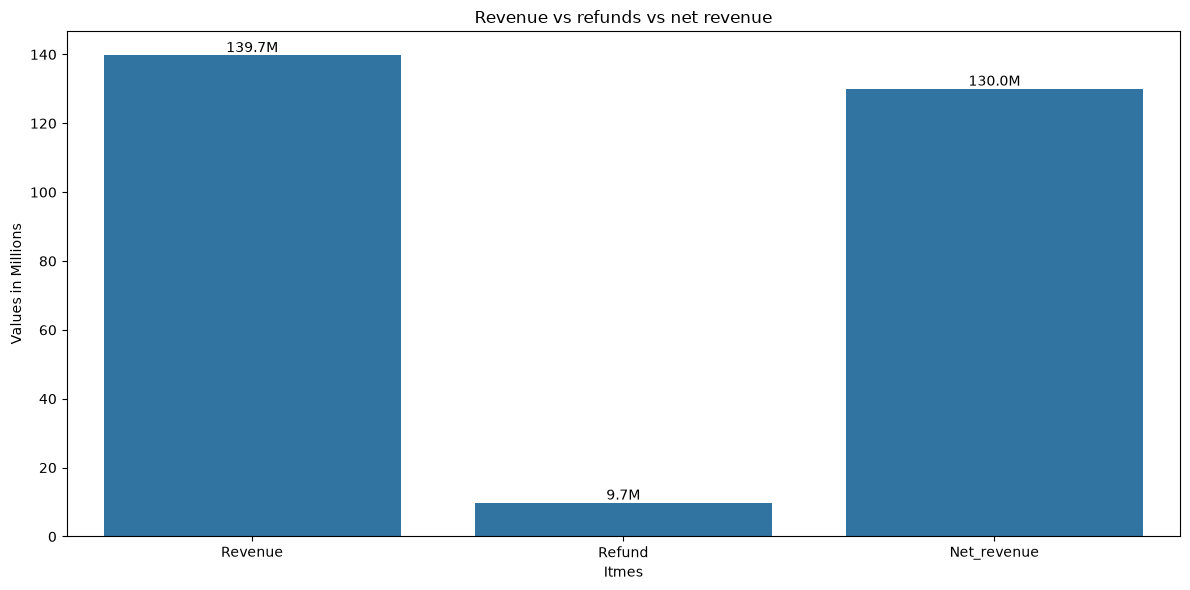

In [86]:
plt.figure(figsize=(12,6))
a = sns.barplot(data = d, x = 'items', y = 'm')
a.bar_label(a.containers[0], fmt = '%.1fM')
plt.title('Revenue vs refunds vs net revenue')
plt.xlabel('Itmes')
plt.ylabel('Values in Millions')
plt.tight_layout()
plt.show()

## 2. Refund money by category

In [87]:
cat

,category,refund_amount,sales_amount,refund_m,refund_pct
2,Electronics,5871701.68,87058760.11,5.871702,6.744527
5,Home & Kitchen,981405.87,16288283.11,0.981406,6.025226
7,Toys,932348.66,10950424.70,0.932349,8.514269
6,Sports,845458.76,9514392.37,0.845459,8.886104
3,Fashion,726854.69,10211480.52,0.726855,7.118015
0,Beauty,187669.94,2862252.82,0.187670,6.556721
1,Books,164273.94,2265856.54,0.164274,7.249971
4,Grocery,39110.24,568711.00,0.039110,6.876997


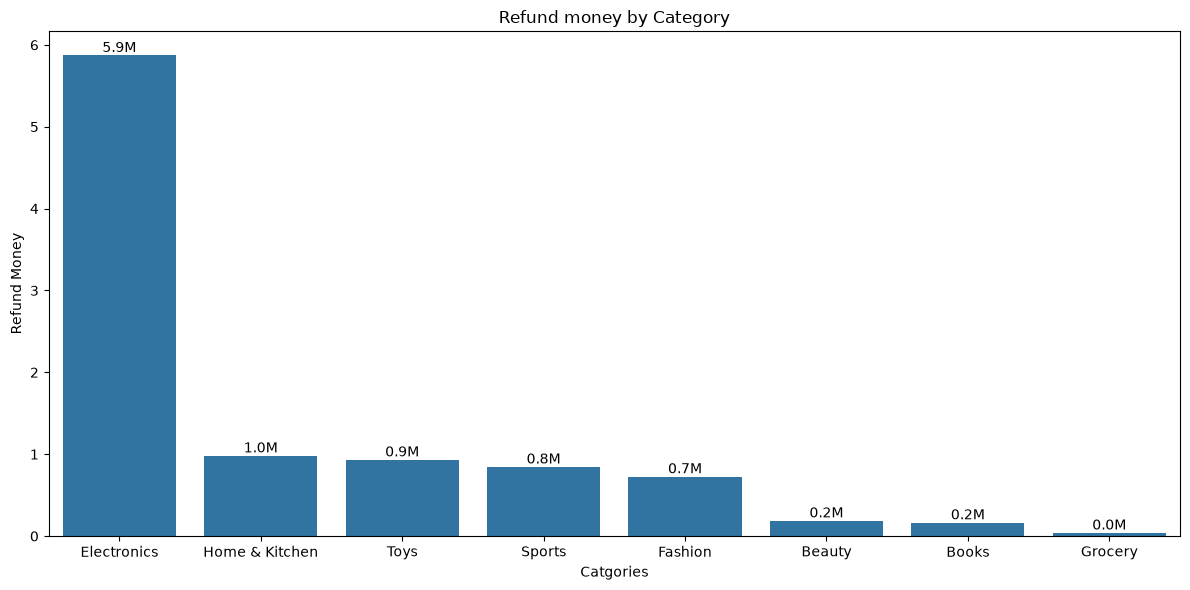

In [91]:
plt.figure(figsize = (12,6))
a = sns.barplot(data = cat, x = 'category', y = 'refund_m')
a.bar_label(a.containers[0], fmt = '%.1fM')
plt.title('Refund money by Category')
plt.xlabel('Catgories')
plt.ylabel('Refund Money')
plt.tight_layout()
plt.show()

### 3. Refund as a percent of each category’s revenue

In [95]:
cat

,category,refund_amount,sales_amount,refund_m,refund_pct
2,Electronics,5871701.68,87058760.11,5.871702,6.744527
5,Home & Kitchen,981405.87,16288283.11,0.981406,6.025226
7,Toys,932348.66,10950424.70,0.932349,8.514269
6,Sports,845458.76,9514392.37,0.845459,8.886104
3,Fashion,726854.69,10211480.52,0.726855,7.118015
0,Beauty,187669.94,2862252.82,0.187670,6.556721
1,Books,164273.94,2265856.54,0.164274,7.249971
4,Grocery,39110.24,568711.00,0.039110,6.876997


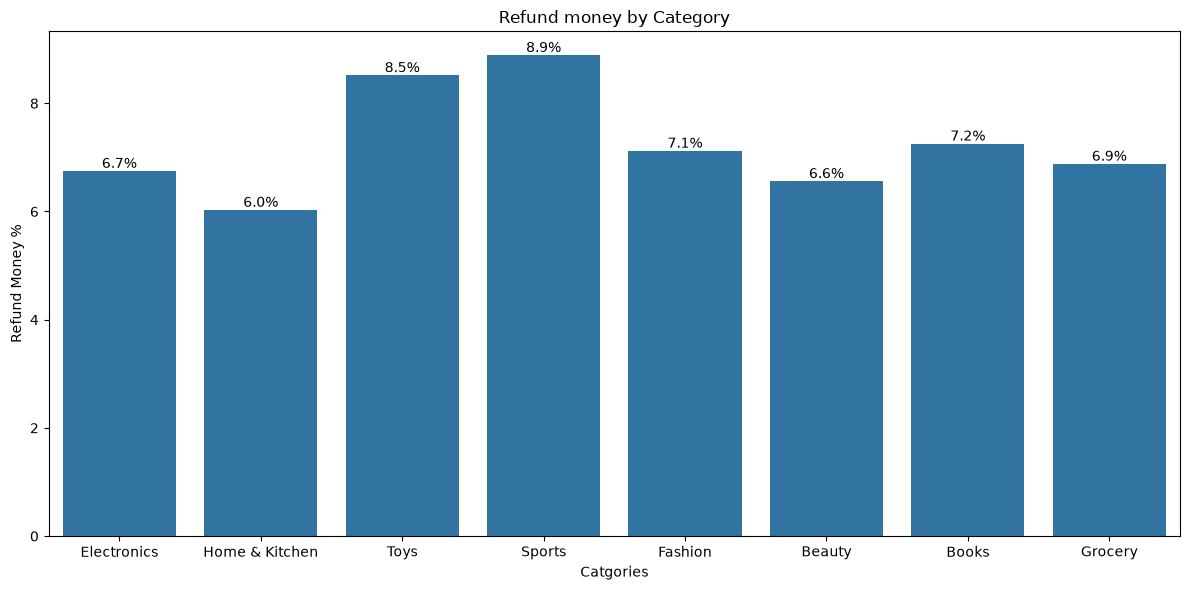

In [94]:
plt.figure(figsize = (12,6))
a = sns.barplot(data = cat, x = 'category', y = 'refund_pct')
a.bar_label(a.containers[0], fmt = '%.1f%%')
plt.title('Refund money by Category')
plt.xlabel('Catgories')
plt.ylabel('Refund Money %')
plt.tight_layout()
plt.show()

In [96]:
(6.7+6+8.5+8.9+7.1+6.6+7.2+6.9)/8

7.237500000000001

## CONCLUSION

## Recommendations